<h1 id="Image-Captioning"><center>Image Captioning</center></h1><center>Shan-Hung Wu &amp; DataLab</center>
<center>Fall 2026</center>

<p>In the last Lab, you have learned how to implement machine translation, where the task is to transform a sentence S written in a source language, into its translation T in the target language.</p>
<p>The model architecture in machine translation is intuitionistic. An “encoder” RNN reads the source sentence and transforms it into a rich fixed-length vector representation, which in turn used as the initial hidden state of a “decoder” RNN that generates the target
sentence.</p>
<p>So, what if we look at the images instead of reading the sentences in encoder? That is to say, we use a combination of convolutional neural networks to obtain the vectorial representation of images and recurrent neural networks to decode those representations into natural language sentences. The description must capture not only the objects contained in an image, but it also must express how these objects relate to each other as well as their attributes and the activities they are involved in.</p>
<p>This is the <strong>Image Captioning</strong>, a very important challenge for machine learning algorithms, as it amounts to mimicking
the remarkable human ability to compress huge amounts of salient visual information into descriptive language.</p>

<h2 id="m-RNN"><a href="https://arxiv.org/abs/1410.1090">m-RNN</a></h2>

<center><img src="./m-RNN.png" style="width: 90%"/></center><p>This paper presents a multimodal Recurrent Neural Network (m-RNN) model for generating novel sentence descriptions to explain the content of images.</p>
<blockquote>To the best of our knowledge, this is the first work that incorporates the Recurrent Neural Network in a deep multimodal architecture.</blockquote><p>The whole m-RNN architecture contains 3 parts: a language model part, an image part and a multimodal part.</p>
<ul>
<li>The language model part learns the dense feature embedding for each word in the dictionary and stores the semantic temporal context in recurrent layers. </li>
<li>The image part contains a deep Convolutional Neural Network (CNN) which extracts image features. </li>
<li>The multimodal part connects the language model and the deep CNN together by a one-layer representation.</li>
</ul>
<p>It must be emphasized that:</p>
<ol>
<li>The image part is AlexNet, which connects the seventh layer of AlexNet to the multimodal layer.</li>
<li>This model feeds the image at each time step.</li>
</ol>

<h2 id="NIC"><a href="https://arxiv.org/abs/1411.4555">NIC</a></h2><p><center><img src="./NIC.png" style="width: 35%"/></center>
This paper presents a generative model based on a deep recurrent architecture that combines recent advances in computer
vision and machine translation and that can be used to generate natural sentences describing an image. The model uses the encoder-decoder framework of machine translation, which replaces the encoder RNN by a deep convolution neural network.</p>
<p>It must be emphasized that:</p>
<ol>
<li>The model uses a more powerful CNN in the encoder, which yields the best performance on the ILSVRC 2014 classification competition at that time.</li>
<li>To deal with vanishing and exploding gradients, LSTM was introduced in the decoder to generate sentences based on the fixed-length vector representations from CNN.</li>
<li>The image is only input once, at t = -1, to inform the LSTM about the image contents.<blockquote>We empirically verified that feeding the image at each time step as an extra input yields inferior results, as the network can explicitly exploit noise in the image and overfits more easily.</blockquote></li>
</ol>

<h2 id="Attention-Based"><a href="https://arxiv.org/abs/1502.03044">Attention-Based</a></h2><center><img src="./attention.png" style="width: 50%"/></center><p>One of the most curious facets of the human visual system is the presence of attention. Rather than compress an entire image into a static representation, attention allows for salient features to dynamically come to the forefront as needed. This is especially important when there is a lot of clutter in an image.</p>
<p>Using representations (such as those from the top layer of a convnet) that distill information in image down to the
most salient objects is one effective solution that has been widely adopted in previous work. Unfortunately, this has
one potential drawback of losing information which could be useful for richer, more descriptive captions.</p>
<p>Using more low-level representation can help preserve this information. However, working with these features necessitates a powerful mechanism to steer the model to information important to the task at hand.</p>
<p>This paper describes approaches to caption generation that attempt to incorporate a form of attention with two variants:</p>
<ol>
<li>a “soft” deterministic attention mechanism trainable by standard back-propagation methods</li>
<li>a “hard” stochastic attention mechanism trainable by maximizing an approximate variational lower bound or equivalently by REINFORCE</li>
</ol>

<p>The paper above introducing the attention-based model was published at <a href="http://proceedings.mlr.press/v37/xuc15.pdf">ICML-2015</a>. Since then, there has been a lot of models developed by researchers, and the state of the art was broken again and again.</p>
<p>If you are interested in this field, you can also click on this <a href="https://paperswithcode.com/task/image-captioning">link</a>, which summarizes many excellent papers in image captioning.</p>
<p>Now, let's begin with our implementation.</p>

<h2 id="Image-Captioning">Image Captioning</h2>

<p>Given an image like the example below, our goal is to generate a caption such as "a surfer riding on a wave".</p>
<p><img alt="Man Surfing" src="https://tensorflow.org/images/surf.jpg"/></p>
<p><em><a href="https://commons.wikimedia.org/wiki/Surfing#/media/File:Surfing_in_Hawaii.jpg">Image Source</a>; License: Public Domain</em></p>
<p>To accomplish this, you'll use an attention-based model, which enables us to see what parts of the image the model focuses on as it generates a caption.</p>
<p><img alt="Prediction" src="https://tensorflow.org/images/imcap_prediction.png"/></p>
<p>The model architecture is similar to <a href="https://arxiv.org/abs/1502.03044">Show, Attend and Tell: Neural Image Caption Generation with Visual Attention</a>.</p>
<p>This notebook is an end-to-end example. When you run the notebook, it downloads the <a href="http://cocodataset.org/#home">MS-COCO</a> dataset, preprocesses and caches a subset of images using Inception V3, trains an encoder-decoder model, and generates captions on new images using the trained model.</p>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


In [3]:
# You'll generate plots of attention in order to see which parts of an image
# our model focuses on during captioning
import matplotlib.pyplot as plt

# Scikit-learn includes many helpful utilities
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

import re
import numpy as np
import os
import time
import json
from glob import glob
from PIL import Image
import pickle
from collections import Counter

<h2 id="Download-and-prepare-the-MS-COCO-dataset">Download and prepare the MS-COCO dataset</h2><p>You will use the <a href="http://cocodataset.org/#home">MS-COCO dataset</a> to train our model. The dataset contains over <strong>82,000 images</strong>, each of which has <strong>at least 5 different caption annotations</strong>. The code below downloads and extracts the dataset automatically.</p>
<p><strong>Caution: large download ahead</strong>. You'll use the training set, which is a <strong>13GB</strong> file.</p>

In [ ]:
import urllib.request
import zipfile

directory = './'  # where you want to put the zip files and images

def download_and_extract(url, dest_zip):
    if not os.path.exists(dest_zip):
        urllib.request.urlretrieve(url, dest_zip)
    with zipfile.ZipFile(dest_zip) as f:
        f.extractall(directory)

if not os.path.exists(directory + 'annotations/captions_train2014.json'):
    download_and_extract(
        'http://images.cocodataset.org/annotations/annotations_trainval2014.zip',
        directory + 'captions.zip')
annotation_file = directory + 'annotations/captions_train2014.json'

if not os.path.exists(directory + 'train2014/'):
    download_and_extract(
        'http://images.cocodataset.org/zips/train2014.zip',
        directory + 'train2014.zip')
PATH = directory + 'train2014/'

<h2 id="Optional:-limit-the-size-of-the-training-set">Optional: limit the size of the training set</h2><p>To speed up training for this tutorial, you'll use a subset of 30,000 captions and their corresponding images to train our model. Choosing to use more data would result in improved captioning quality.</p>

In [37]:
## delete when publish
import urllib.request
import zipfile
directory = './'  # where you want to put the zip files and images
annotation_file = directory + 'annotations/captions_train2014.json'
PATH = directory + 'train2014/'

In [6]:
# Read the json file
with open(annotation_file, 'r') as f:
    annotations = json.load(f)

# Store captions and image names in vectors
all_captions = []
all_img_name_vector = []

for annot in annotations['annotations']:
    caption = '<start> ' + annot['caption'] + ' <end>'
    image_id = annot['image_id']
    full_coco_image_path = PATH + 'COCO_train2014_' + '%012d.jpg' % (image_id)

    all_img_name_vector.append(full_coco_image_path)
    all_captions.append(caption)

# Shuffle captions and image_names together
# Set a random state
train_captions, img_name_vector = shuffle(all_captions,
                                          all_img_name_vector,
                                          random_state=1)

# Select the first 30,000 captions from the shuffled set
num_examples = 30000
train_captions = train_captions[:num_examples]
img_name_vector = img_name_vector[:num_examples]

In [7]:
len(train_captions), len(all_captions), len(
    [name for name in os.listdir(PATH) if os.path.isfile(os.path.join(PATH, name))])

(30000, 414113, 82783)

<p>There are tottal 82,783 images with 414,113 captions, but we only use 30,000 captions and their corresponding images to train our model.</p>

<h2 id="Preprocess-the-images-using-InceptionV3">Preprocess the images using InceptionV3</h2><p>Next, you will use InceptionV3 (which is pretrained on Imagenet) to classify each image. You will extract features from the last convolutional layer.</p>
<p>First, you will convert the images into InceptionV3's expected format by:</p>
<ul>
<li>Resizing the image to 299px by 299px</li>
<li><a href="https://cloud.google.com/tpu/docs/inception-v3-advanced#preprocessing_stage">Preprocess the images</a> using the <a href="https://www.tensorflow.org/api_docs/python/tf/keras/applications/inception_v3/preprocess_input">preprocess_input</a> method to normalize the image so that it contains pixels in the range of -1 to 1, which matches the format of the images used to train InceptionV3.</li>
</ul>

`tf.keras.applications.inception_v3.preprocess_input` scales pixels to **[-1, 1]** -- that's the preprocessing Keras' InceptionV3 checkpoint (a TF-Slim port) was trained with. torchvision's pretrained InceptionV3 checkpoint is a *different* set of trained weights, converted with **standard torchvision preprocessing instead** ([0,1] then ImageNet mean/std normalization) -- so to correctly use torchvision's own pretrained weights we must use *torchvision's* preprocessing, not literally translate `preprocess_input`'s `[-1,1]` scaling.

In [8]:
INCEPTION_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
INCEPTION_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def load_image(image_path):
    img = Image.open(image_path).convert('RGB').resize((299, 299))
    img = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
    img = (img - INCEPTION_MEAN) / INCEPTION_STD
    return img, image_path

<h2 id="Initialize-InceptionV3-and-load-the-pretrained-Imagenet-weights">Initialize InceptionV3 and load the pretrained Imagenet weights</h2><p>Now you'll create a tf.keras model where the output layer is the last convolutional layer in the InceptionV3 architecture. The shape of the output of this layer is <code>8x8x2048</code>. You use the last convolutional layer because you are using attention in this example. You don't perform this initialization during training because it could become a bottleneck.</p>
<ul>
<li>You forward each image through the network and store the resulting vector in a dictionary (image_name --&gt; feature_vector).</li>
<li>After all the images are passed through the network, you pickle the dictionary and save it to disk.</li>
</ul>

In [9]:
from torchvision.models import inception_v3, Inception_V3_Weights

class InceptionFeatureExtractor(nn.Module):
    """Equivalent of `tf.keras.Model(new_input, image_model.layers[-1].output)`:
    InceptionV3 truncated right before the global-pool/classification head.
    `Mixed_7c` is torchvision's name for that last Inception block; its
    output is (batch, 2048, 8, 8) for a 299x299 input, matching Keras'
    (batch, 8, 8, 2048) (just channels-first instead of channels-last).
    """
    def __init__(self):
        super().__init__()
        net = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1, aux_logits=True)
        net.eval()
        net.requires_grad_(False)
        self.inception = net
        self._feat = None
        self.inception.Mixed_7c.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self._feat = out

    @torch.no_grad()
    def forward(self, x):
        self.inception(x)
        return self._feat


image_features_extract_model = InceptionFeatureExtractor().to(device)

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /home/bigboss/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100%|███████████████████████████████████████| 104M/104M [00:09<00:00, 11.7MB/s]


<h2 id="Caching-the-features-extracted-from-InceptionV3">Caching the features extracted from InceptionV3</h2><p>You will pre-process each image with InceptionV3 and cache the output to disk. Caching the output in RAM would be faster but also memory intensive, requiring 8 * 8 * 2048 floats per image. At the time of writing, this exceeds the memory limitations of Colab (currently 12GB of memory).</p>
<p>Performance could be improved with a more sophisticated caching strategy (for example, by sharding the images to reduce random access disk I/O), but that would require more code.</p>
<p>The caching will take about 10 minutes to run in Colab with a GPU. If you'd like to see a progress bar, you can:</p>
<ol>
<li><p>install <a href="https://github.com/tqdm/tqdm">tqdm</a>:</p>
<p><code>!pip install -q tqdm</code></p>
</li>
<li><p>Import tqdm:</p>
<p><code>from tqdm import tqdm</code></p>
</li>
<li><p>Change the following line:</p>
<p><code>for img, path in image_dataset:</code></p>
<p>to:</p>
<p><code>for img, path in tqdm(image_dataset):</code></p>
</li>
</ol>

<h5 id="Note:-the-code-below-would-take-more-than-12GB-of-memory-to-save-the-features-extracted-by-inception_v3">Note: the code below would take more than 12GB of memory to save the features extracted by inception_v3</h5>

In [10]:
from tqdm import tqdm

class ImagePathDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img, path = load_image(self.paths[idx])
        return img, path


# Get unique images
encode_train = sorted(set(img_name_vector))

# Feel free to change batch_size according to your system configuration
image_loader = DataLoader(ImagePathDataset(encode_train), batch_size=16,
                           num_workers=4)

for img, path in tqdm(image_loader):
    batch_features = image_features_extract_model(img.to(device))
    # (B, 2048, 8, 8) -> (B, 64, 2048), matching Keras' tf.reshape
    batch_features = batch_features.flatten(2).permute(0, 2, 1)

    # save the preprocessed images to .npy files
    for bf, p in zip(batch_features, path):
        np.save(p, bf.cpu().numpy())

100%|██████████████████████████████████████| 1622/1622 [01:11<00:00, 22.58it/s]


<h2 id="Preprocess-and-tokenize-the-captions">Preprocess and tokenize the captions</h2><ul>
<li>First, you'll tokenize the captions (for example, by splitting on spaces). This gives us a  vocabulary of all of the unique words in the data (for example, "surfing", "football", and so on).</li>
<li>Next, you'll limit the vocabulary size to the top 5,000 words (to save memory). You'll replace all other words with the token "UNK" (unknown).</li>
<li>You then create word-to-index and index-to-word mappings.</li>
<li>Finally, you pad all sequences to be the same length as the longest one.</li>
</ul>

In [11]:
# Find the maximum length of any caption in our dataset
def calc_max_length(tensor):
    return max(len(t) for t in tensor)

There's no PyTorch equivalent of `tf.keras.preprocessing.text.Tokenizer`, so we reimplement the bits used here: word-frequency ranking, an `oov_token` for out-of-vocabulary words, a `num_words` cap, and the `filters` string of punctuation to strip (Keras strips those characters before splitting on whitespace).

In [12]:
class SimpleTokenizer:
    def __init__(self, num_words=None, oov_token=None, filters=''):
        self.num_words = num_words
        self.oov_token = oov_token
        self._filter_table = str.maketrans({c: ' ' for c in filters})
        self.word_index = {}
        self.index_word = {}

    def _tokenize(self, text):
        return text.lower().translate(self._filter_table).split()

    def fit_on_texts(self, texts):
        counts = Counter()
        for text in texts:
            counts.update(self._tokenize(text))
        vocab = [w for w, _ in counts.most_common()]
        if self.num_words is not None:
            budget = self.num_words - (2 if self.oov_token else 1)
            vocab = vocab[:budget]

        self.word_index = {}
        idx = 1
        if self.oov_token is not None:
            self.word_index[self.oov_token] = idx
            idx += 1
        for w in vocab:
            self.word_index[w] = idx
            idx += 1
        self.index_word = {i: w for w, i in self.word_index.items()}

    def texts_to_sequences(self, texts):
        oov_idx = self.word_index.get(self.oov_token) if self.oov_token else None
        seqs = []
        for text in texts:
            seq = []
            for w in self._tokenize(text):
                if w in self.word_index:
                    seq.append(self.word_index[w])
                elif oov_idx is not None:
                    seq.append(oov_idx)
            seqs.append(seq)
        return seqs


def pad_sequences(sequences, maxlen=None, padding='post', value=0):
    if maxlen is None:
        maxlen = max(len(s) for s in sequences)
    out = np.full((len(sequences), maxlen), value, dtype=np.int64)
    for i, seq in enumerate(sequences):
        seq = seq[:maxlen]
        if padding == 'post':
            out[i, :len(seq)] = seq
        else:
            out[i, -len(seq):] = seq
    return out

In [13]:
# Choose the top 5000 words from the vocabulary
top_k = 5000
tokenizer = SimpleTokenizer(num_words=top_k, oov_token="<unk>",
                             filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~ ')
tokenizer.fit_on_texts(train_captions)
train_seqs = tokenizer.texts_to_sequences(train_captions)

<>:4: SyntaxWarning: invalid escape sequence '\]'
<>:4: SyntaxWarning: invalid escape sequence '\]'
/tmp/ipykernel_18558/3304392480.py:4: SyntaxWarning: invalid escape sequence '\]'
  filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~ ')


In [14]:
tokenizer.word_index['<pad>'] = 0
tokenizer.index_word[0] = '<pad>'

In [15]:
# Create the tokenized vectors
train_seqs = tokenizer.texts_to_sequences(train_captions)

In [16]:
# Pad each vector to the max_length of the captions
# If you do not provide a max_length value, pad_sequences calculates it automatically
cap_vector = pad_sequences(train_seqs, padding='post')

In [17]:
# Calculates the max_length, which is used to store the attention weights
max_length = calc_max_length(train_seqs)

<h2 id="Split-the-data-into-training-and-testing">Split the data into training and testing</h2>

In [18]:
# Create training and validation sets using an 80-20 split
img_name_train, img_name_val, cap_train, cap_val = train_test_split(
    img_name_vector, cap_vector, test_size=0.2, random_state=0)

In [19]:
len(img_name_train), len(cap_train), len(img_name_val), len(cap_val)

(24000, 24000, 6000, 6000)

<h2 id="Create-a-DataLoader-for-training">Create a DataLoader for training</h2>

<p>Our images and captions are ready! Next, let's create a tf.data dataset to use for training our model.</p>

In [20]:
# Feel free to change these parameters according to your system's configuration

BATCH_SIZE = 100
embedding_dim = 256
units = 512
vocab_size = len(tokenizer.word_index) + 1
num_steps = len(img_name_train) // BATCH_SIZE
# Shape of the vector extracted from InceptionV3 is (64, 2048)
# These two variables represent that vector shape
features_shape = 2048
attention_features_shape = 64

Where TF loads the cached `.npy` features via `tf.numpy_function` inside the `tf.data` pipeline, a PyTorch `Dataset.__getitem__` can just call `np.load` directly -- no special wrapping needed to mix NumPy I/O into the data-loading path.

In [21]:
class CaptionDataset(Dataset):
    def __init__(self, img_names, captions):
        self.img_names = img_names
        self.captions = captions

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_tensor = np.load(self.img_names[idx] + '.npy')
        return torch.from_numpy(img_tensor), torch.from_numpy(self.captions[idx]).long()


dataset = DataLoader(CaptionDataset(img_name_train, cap_train),
                      batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=4, drop_last=True)

<h2 id="Model">Model</h2><p>Fun fact: the decoder below is identical to the one in the example for <a href="https://nthu-datalab.github.io/ml/labs/12-1_Seq2Seq-Learning_Neural-Machine-Translation/12-1_Seq2Seq-Learning_Neural-Machine-Translation.html">Neural Machine Translation with Attention</a>.</p>
<p>The model architecture is inspired by the <a href="https://arxiv.org/pdf/1502.03044.pdf">Show, Attend and Tell</a> paper.</p>
<ul>
<li>In this example, you extract the features from the lower convolutional layer of InceptionV3 giving us a vector of shape (8, 8, 2048).</li>
<li>You squash that to a shape of (64, 2048).</li>
<li>This vector is then passed through the CNN Encoder (which consists of a single Fully connected layer).</li>
<li>The RNN (here GRU) attends over the image to predict the next word.</li>
</ul>

In [22]:
class BahdanauAttention(nn.Module):
    def __init__(self, units, feature_dim, hidden_dim):
        super().__init__()
        self.W1 = nn.Linear(feature_dim, units)
        self.W2 = nn.Linear(hidden_dim, units)
        self.V = nn.Linear(units, 1)

    def forward(self, features, hidden):
        # features (CNN_encoder output) shape == (batch_size, 64, embedding_dim)

        # hidden shape == (batch_size, hidden_size)
        # hidden_with_time_axis shape == (batch_size, 1, hidden_size)
        hidden_with_time_axis = hidden.unsqueeze(1)

        # score shape == (batch_size, 64, units)
        score = torch.tanh(self.W1(features) + self.W2(hidden_with_time_axis))

        # attention_weights shape == (batch_size, 64, 1)
        attention_weights = F.softmax(self.V(score), dim=1)

        # context_vector shape after sum == (batch_size, embedding_dim)
        context_vector = attention_weights * features
        context_vector = context_vector.sum(dim=1)

        return context_vector, attention_weights

In [23]:
class CNN_Encoder(nn.Module):
    # Since you have already extracted the features and dumped them
    # This encoder passes those features through a Fully connected layer
    def __init__(self, feature_dim, embedding_dim):
        super().__init__()
        # shape after fc == (batch_size, 64, embedding_dim)
        self.fc = nn.Linear(feature_dim, embedding_dim)

    def forward(self, x):
        x = self.fc(x)
        return F.relu(x)

In [24]:
class RNN_Decoder(nn.Module):
    def __init__(self, embedding_dim, units, vocab_size):
        super().__init__()
        self.units = units

        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        # GRU input is [context_vector; embedded_word] -> embedding_dim * 2
        self.gru = nn.GRU(embedding_dim * 2, units, batch_first=True)
        self.fc1 = nn.Linear(units, units)
        self.fc2 = nn.Linear(units, vocab_size)

        self.attention = BahdanauAttention(units, feature_dim=embedding_dim, hidden_dim=units)

    def forward(self, x, features, hidden):
        # defining attention as a separate model
        context_vector, attention_weights = self.attention(features, hidden)

        # x shape after passing through embedding == (batch_size, 1, embedding_dim)
        x = self.embedding(x)

        # x shape after concatenation == (batch_size, 1, embedding_dim + embedding_dim)
        x = torch.cat([context_vector.unsqueeze(1), x], dim=-1)

        # passing the concatenated vector to the GRU
        output, state = self.gru(x, hidden.unsqueeze(0))

        # shape == (batch_size, 1, units)
        x = self.fc1(output)

        # x shape == (batch_size * 1, units)
        x = x.reshape(-1, x.shape[2])

        # output shape == (batch_size, vocab)
        x = self.fc2(x)

        return x, state.squeeze(0), attention_weights

    def reset_state(self, batch_size):
        return torch.zeros(batch_size, self.units, device=device)

In [25]:
encoder = CNN_Encoder(features_shape, embedding_dim).to(device)
decoder = RNN_Decoder(embedding_dim, units, vocab_size).to(device)

In [26]:
optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()))

def loss_function(real, pred):
    mask = (real != 0).float()
    loss_ = F.cross_entropy(pred, real, reduction='none')

    loss_ = loss_ * mask

    return loss_.mean()

<h2 id="Checkpoint">Checkpoint</h2>

In [27]:
checkpoint_dir = './checkpoints/train'
os.makedirs(checkpoint_dir, exist_ok=True)
MAX_TO_KEEP = 3

def save_checkpoint(epoch):
    path = os.path.join(checkpoint_dir, f'ckpt-{epoch}.pt')
    torch.save({'encoder': encoder.state_dict(), 'decoder': decoder.state_dict(),
                'optimizer': optimizer.state_dict(), 'epoch': epoch}, path)
    # keep only the most recent MAX_TO_KEEP checkpoints (like CheckpointManager)
    ckpts = sorted(glob(os.path.join(checkpoint_dir, 'ckpt-*.pt')),
                   key=lambda p: int(p.split('-')[-1].split('.')[0]))
    for old in ckpts[:-MAX_TO_KEEP]:
        os.remove(old)

def latest_checkpoint():
    ckpts = sorted(glob(os.path.join(checkpoint_dir, 'ckpt-*.pt')),
                   key=lambda p: int(p.split('-')[-1].split('.')[0]))
    return ckpts[-1] if ckpts else None

In [28]:
start_epoch = 0
ckpt = latest_checkpoint()
if ckpt:
    checkpoint = torch.load(ckpt, map_location=device)
    encoder.load_state_dict(checkpoint['encoder'])
    decoder.load_state_dict(checkpoint['decoder'])
    optimizer.load_state_dict(checkpoint['optimizer'])
    start_epoch = checkpoint['epoch']

<h2 id="Training">Training</h2><ul>
<li>You extract the features stored in the respective <code>.npy</code> files and then pass those features through the encoder.</li>
<li>The encoder output, hidden state(initialized to 0) and the decoder input (which is the start token) is passed to the decoder.</li>
<li>The decoder returns the predictions and the decoder hidden state.</li>
<li>The decoder hidden state is then passed back into the model and the predictions are used to calculate the loss.</li>
<li>Use teacher forcing to decide the next input to the decoder.</li>
<li>Teacher forcing is the technique where the target word is passed as the next input to the decoder.</li>
<li>The final step is to calculate the gradients and apply it to the optimizer and backpropagate.</li>
</ul>

In [29]:
# adding this in a separate cell because if you run the training cell
# many times, the loss_plot array will be reset
loss_plot = []

In [30]:
def train_step(img_tensor, target):
    loss = 0.0

    # initializing the hidden state for each batch
    # because the captions are not related from image to image
    hidden = decoder.reset_state(batch_size=target.shape[0])

    dec_input = torch.full((target.shape[0], 1), tokenizer.word_index['<start>'],
                            dtype=torch.long, device=device)

    optimizer.zero_grad()
    features = encoder(img_tensor)

    for i in range(1, target.shape[1]):
        # passing the features through the decoder
        predictions, hidden, _ = decoder(dec_input, features, hidden)

        loss = loss + loss_function(target[:, i], predictions)

        # using teacher forcing
        dec_input = target[:, i].unsqueeze(1)

    total_loss = loss / target.shape[1]

    loss.backward()
    optimizer.step()

    return loss.item(), total_loss.item()

In [31]:
EPOCHS = 50
start = time.time()
for epoch in range(start_epoch, EPOCHS):

    total_loss = 0

    for batch, (img_tensor, target) in tqdm(enumerate(dataset), total=num_steps):
        if batch >= num_steps:
            break
        img_tensor, target = img_tensor.to(device), target.to(device)
        batch_loss, t_loss = train_step(img_tensor, target)
        total_loss += t_loss

    # storing the epoch end loss value to plot later
    loss_plot.append(total_loss / num_steps)

    if epoch % 5 == 0:
        save_checkpoint(epoch + 1)

    print('Epoch {} Loss {:.6f}'.format(epoch + 1, total_loss / num_steps))
print('Time taken for {} epoch {} sec\n'.format(EPOCHS, time.time() - start))

100%|████████████████████████████████████████| 240/240 [01:01<00:00,  3.89it/s]


Epoch 1 Loss 0.977486


100%|████████████████████████████████████████| 240/240 [01:01<00:00,  3.93it/s]

Epoch 2 Loss 0.725281



100%|████████████████████████████████████████| 240/240 [01:02<00:00,  3.87it/s]

Epoch 3 Loss 0.636294


... (90 outputs left out)


100%|████████████████████████████████████████| 240/240 [01:01<00:00,  3.92it/s]

Epoch 49 Loss 0.043384



100%|████████████████████████████████████████| 240/240 [01:01<00:00,  3.89it/s]

Epoch 50 Loss 0.043146
Time taken for 50 epoch 3049.3815541267395 sec



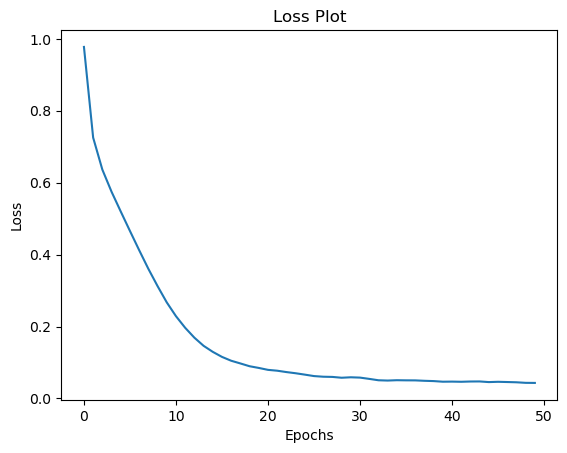

In [32]:
plt.plot(loss_plot)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Plot')
plt.show()

<h2 id="Caption!">Caption!</h2><ul>
<li>The evaluate function is similar to the training loop, except you don't use teacher forcing here. The input to the decoder at each time step is its previous predictions along with the hidden state and the encoder output.</li>
<li>Stop predicting when the model predicts the end token.</li>
<li>And store the attention weights for every time step.</li>
</ul>

In [33]:
@torch.no_grad()
def evaluate(image):
    encoder.eval(); decoder.eval()
    attention_plot = np.zeros((max_length, attention_features_shape))

    hidden = decoder.reset_state(batch_size=1)

    temp_input = load_image(image)[0].unsqueeze(0).to(device)
    img_tensor_val = image_features_extract_model(temp_input)
    img_tensor_val = img_tensor_val.flatten(2).permute(0, 2, 1)

    features = encoder(img_tensor_val)

    dec_input = torch.tensor([[tokenizer.word_index['<start>']]], device=device)
    result = []

    for i in range(max_length):
        predictions, hidden, attention_weights = decoder(dec_input, features, hidden)

        attention_plot[i] = attention_weights.reshape(-1).cpu().numpy()

        predicted_id = predictions[0].argmax().item()
        result.append(tokenizer.index_word[predicted_id])

        if tokenizer.index_word[predicted_id] == '<end>':
            return result, attention_plot

        dec_input = torch.tensor([[predicted_id]], device=device)

    attention_plot = attention_plot[:len(result), :]
    return result, attention_plot

In [34]:
def plot_attention(image, result, attention_plot):
    temp_image = np.array(Image.open(image))

    fig = plt.figure(figsize=(10, 10))

    len_result = len(result)
    for l in range(len_result):
        temp_att = np.resize(attention_plot[l], (8, 8))
        ax = fig.add_subplot(len_result // 2, len_result // 2, l + 1)
        ax.set_title(result[l])
        img = ax.imshow(temp_image)
        ax.imshow(temp_att, cmap='gray', alpha=0.6, extent=img.get_extent())

    plt.tight_layout()
    plt.show()

Real Caption: <start> a group of people sitting at a table with glasses of wine <end>
Prediction Caption: three men sitting at a table with a boat one man and a woman at a table <end>


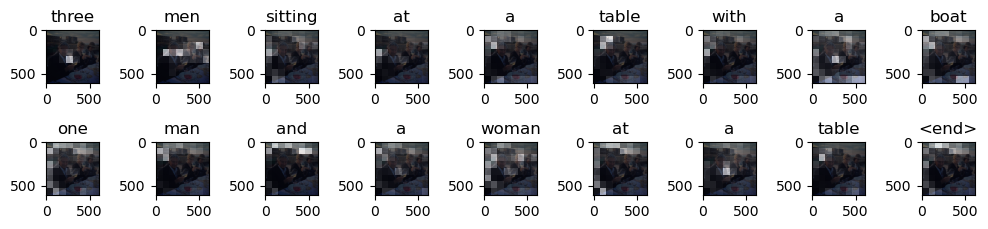

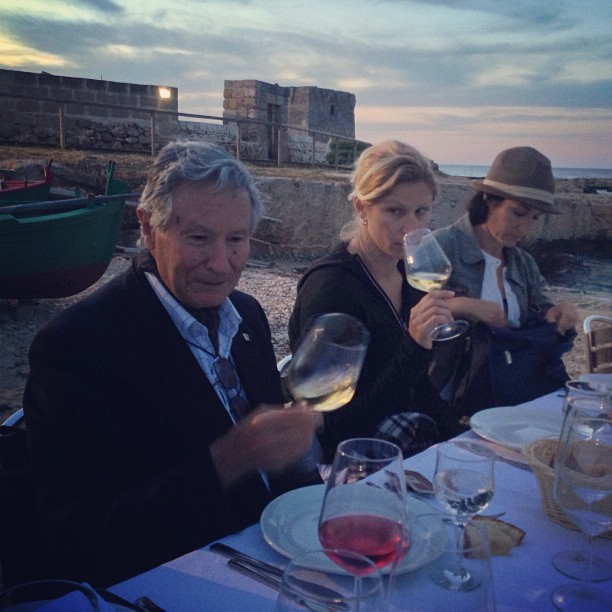

In [35]:
# captions on the validation set
rid = np.random.randint(0, len(img_name_val))
image = img_name_val[rid]
real_caption = ' '.join([tokenizer.index_word[i] for i in cap_val[rid] if i not in [0]])
result, attention_plot = evaluate(image)

print('Real Caption:', real_caption)
print('Prediction Caption:', ' '.join(result))
plot_attention(image, result, attention_plot)
# opening the image
Image.open(img_name_val[rid])

<h2 id="Try-it-on-your-own-images">Try it on your own images</h2><p>For fun, below we've provided a method you can use to caption your own images with the model we've just trained. Keep in mind, it was trained on a relatively small amount of data, and your images may be different from the training data (so be prepared for weird results!)</p>

Prediction Caption: a surfer riding a wave on top of a surfboard <end>


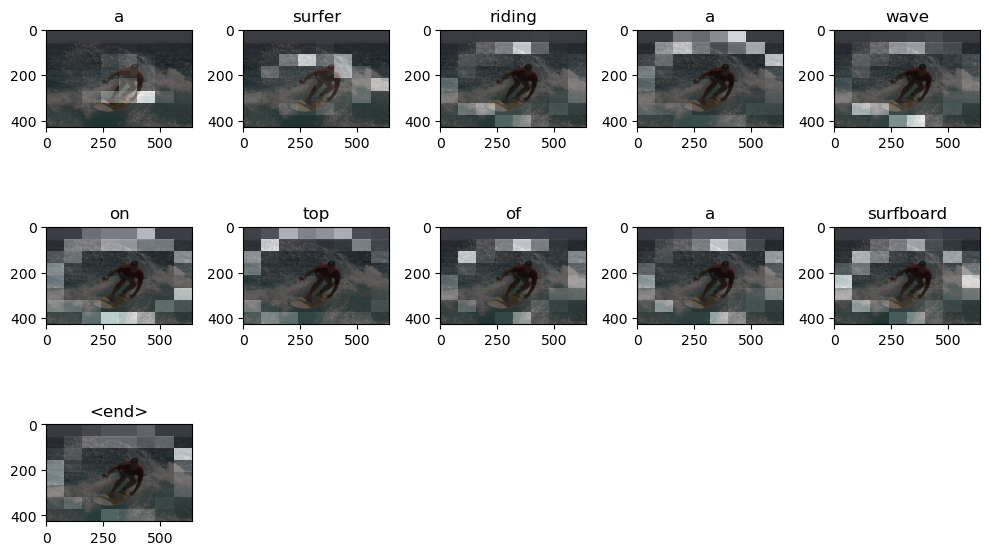

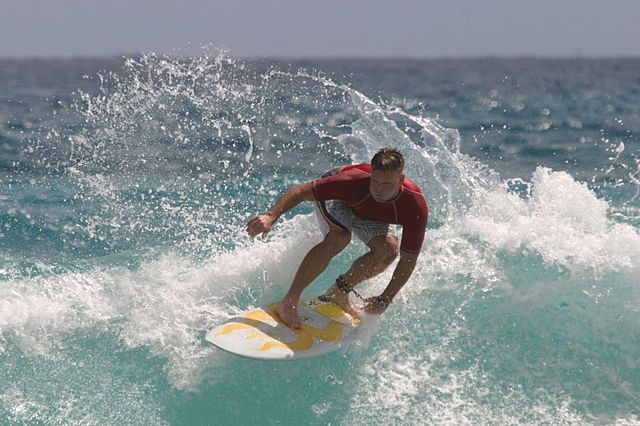

In [38]:
image_url = 'https://tensorflow.org/images/surf.jpg'
image_extension = image_url[-4:]
image_path = 'image' + image_extension
urllib.request.urlretrieve(image_url, image_path)

result, attention_plot = evaluate(image_path)
print('Prediction Caption:', ' '.join(result))
plot_attention(image_path, result, attention_plot)
# opening the image
Image.open(image_path)

<h2 id="Assignment">Assignment</h2>

<p>CAPTCHA (an acronym for "Completely Automated Public Turing test to tell Computers and Humans Apart") is a type of challenge–response test used in computing to determine whether or not the user is human, which is a popular tool since it prevents spam attacks and protects websites from bots.</p>
<p>Captcha asks you to complete the math equation like addition, subtraction, or multiplication. The equation can show up using numbers, letters, or images, therefore bots have no chances.</p>
<center><img src="./captcha.png" style="width: 40%"/></center><p>reCAPTCHA is a CAPTCHA-like system designed to establish that a computer user is human (normally in order to protect websites from bots) and, at the same time, assist in the digitization of books or improve machine learning (even its slogan was “Stop Spam, Read Books”).</p>
<p>It supports two versions. The first asks you to enter some words or digits from the image, and the second asks you to mark the checkbox “I’m not a robot”.</p>
<table>
<tr>
<td>
<a><img src="./recaptcha1.png" style="width: 70%"/></a>
</td>
<td>
<a><img src="./recaptcha2.png" style="width: 70%"/></a>
</td>
</tr>
</table><p>So, as you can see, both tools provide the same functionality increasing the security level of your websites, but the way of how it looks is different. For the more, they also have differences in their features. Let’s compare them:</p>
<center><img src="./cap-recap.png" style="width: 65%"/></center>

<p>CAPTCHAs of English words contain information about the words, so we can use CNN to extract it from images. As you know, RNN can capture the interdependencies between sequences, so it is perfect for generating words by RNN based on the extracted information.</p>
<p>In this assignment, you have to train a captcha-recognizer which can identify English words in images.</p>
<h1 id="You-can-download-the-dataset-here.">You can download the dataset <a href="https://drive.google.com/file/d/1dCTlUjfHp9aiyX_yrFugmWlaG_I-9Gst/view?usp=drive_link">here</a>.</h1><p>Description of Dataset:</p>
<ol>
<li>There are <strong>140,000 images</strong> in this dataset containing 2500 English words (3-5 character lengths) in four different fonts.</li>
<li>In all of these images, there are some noises(lines, curves and points) in different colors.</li>
</ol>
<p>The captcha is shown in the figure below:</p>
<center><img src="./a8.png" style="width: 50%"/></center>

<h3 id="Requirements">Requirements</h3><ol>
<li>You can use any model architectures (or any code above) you want, as long as accomplishing the goal.</li>
<li>You should train your own model architecture. In other words, <strong>except the feature extractor part, do not load the model or any pre-trained weights directly from other sources.</strong><ul>
<li>You can use pretrained inception_v3 as feature extractor; however, <strong>it's not recommended</strong> since inception is pretrained on ImageNet, where the image pattern is quite different to English words.</li>
</ul>
</li>
<li>You should use the <strong>first 100,000 images as training data</strong>, <strong>the next 20,000 as validation data</strong>, and <strong>the rest (final 20,000) as testing data</strong>.<ul>
<li><code>spec_train_val.txt</code> contains the labels of only first 120,000 images.</li>
</ul>
</li>
<li>Only if the whole word matches exactly does it count as correct.</li>
<li>You need to predict the answer to the testing data and write them in a file.</li>
<li>Your testing accuracy should be <strong>at least 90% in validation set</strong>. </li>
</ol>

<h3 id="Hint">Hint</h3><p>In image caption, we expect RNN would output one word at each step.
<p>However, in captcha, we expect RNN would output one <strong>character</strong> at each step. Therefore, before calling <code>Tokenizer</code>, you need to preprocess the training data in a certain form (refer to the text description in the 'Preprocess and tokenize the captions' section), so that we can correctly establish the mapping relationship between <strong>character</strong> and index by the <code>Tokenizer</code>.</p>

<h3 id="Notification:">Notification:</h3><ul>
<li>Submit to <strong>eeclass</strong> your fully executed code file (Lab12-2_{student id}.ipynb), and your answer file (Lab12-2_{student id}.txt).<ul>
<li>Answer file please follow the format as <code>spec_train_val.txt</code>.</li>
</ul>
</li>
<li>Give a <strong>brief report</strong> for every parts you have done.</li>
<li>The deadline will be <strong>2026/11/18 23:59</strong>.</li>
</ul>